Jumlah data: (1010, 8)

5 data teratas sebelum diproses:
   NO                                         NAMA RUMAH       HARGA   LB  \
0   1  Rumah Murah Hook Tebet Timur, Tebet, Jakarta S...  3800000000  220   
1   2  Rumah Modern di Tebet dekat Stasiun, Tebet, Ja...  4600000000  180   
2   3  Rumah Mewah 2 Lantai Hanya 3 Menit Ke Tebet, T...  3000000000  267   
3   4           Rumah Baru Tebet, Tebet, Jakarta Selatan   430000000   40   
4   5  Rumah Bagus Tebet komp Gudang Peluru lt 350m, ...  9000000000  400   

    LT  KT  KM  GRS  
0  220   3   3    0  
1  137   4   3    2  
2  250   4   4    4  
3   25   2   2    0  
4  355   6   5    3  

Kolom setelah menghapus fitur yang tidak digunakan:
['HARGA', 'LB', 'LT', 'KT', 'KM', 'GRS']

Cek missing value awal:
HARGA    0
LB       0
LT       0
KT       0
KM       0
GRS      0
dtype: int64

Cek missing value setelah imputasi:
HARGA    0
LB       0
LT       0
KT       0
KM       0
GRS      0
dtype: int64

Data setelah clipping outlier:
  

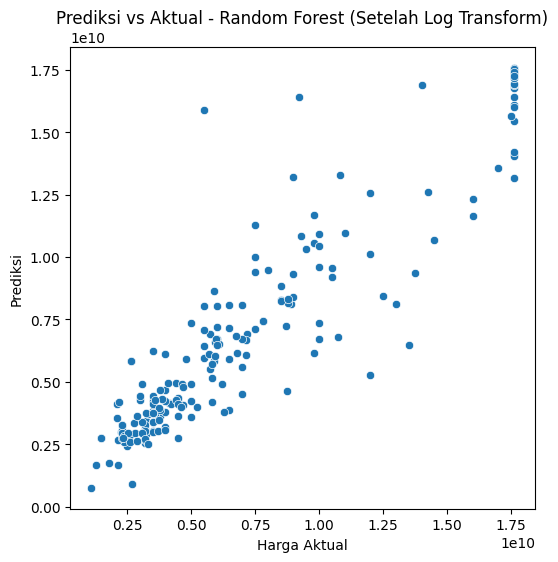


=== 10 FITUR PALING BERPENGARUH ===
num__LT     0.779631
num__LB     0.140086
num__GRS    0.032999
num__KM     0.031215
num__KT     0.016068
dtype: float64


In [2]:
# ============================================================
# PREDIKSI HARGA RUMAH TANPA FITUR "NAMA RUMAH"
# ============================================================

# --- Import Library ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# ============================================================
# 1. LOAD DATA
# ============================================================
data = pd.read_csv("/content/data-rumah.csv")
print("Jumlah data:", data.shape)
print("\n5 data teratas sebelum diproses:")
print(data.head())

# ============================================================
# 2. HAPUS FITUR YANG TIDAK DIPAKAI (misal: Nama Rumah, No, ID)
# ============================================================
drop_cols = ["NAMA RUMAH", "NO", "ID"]
data = data.drop(columns=[col for col in drop_cols if col in data.columns])
print("\nKolom setelah menghapus fitur yang tidak digunakan:")
print(data.columns.tolist())

# ============================================================
# 3. CEK DAN TANGANI MISSING VALUE
# ============================================================
print("\nCek missing value awal:")
print(data.isnull().sum())

# jika ada missing value di numerik → isi median
for col in data.select_dtypes(include=['int64','float64']).columns:
    if data[col].isnull().sum() > 0:
        data[col].fillna(data[col].median(), inplace=True)

# jika ada missing value di kategorikal → isi modus
for col in data.select_dtypes(exclude=['int64','float64']).columns:
    if data[col].isnull().sum() > 0:
        data[col].fillna(data[col].mode()[0], inplace=True)

print("\nCek missing value setelah imputasi:")
print(data.isnull().sum())

# ============================================================
# 4. DETEKSI & CLIPPING OUTLIER (IQR)
# ============================================================
numeric_cols = data.select_dtypes(include=['int64','float64']).columns.tolist()

for col in numeric_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    data[col] = np.clip(data[col], lower, upper)

print("\nData setelah clipping outlier:")
print(data.describe())

# ============================================================
# 5. PEMISAHAN FITUR & TARGET
# ============================================================
X = data.drop(columns=["HARGA"])
y = data["HARGA"]

# ============================================================
# 6. TRANSFORMASI LOG UNTUK TARGET
# ============================================================
y = np.log1p(y)
print("\nContoh nilai target (setelah log transform):")
print(y.head())

# ============================================================
# 7. PEMISAHAN NUMERIK & KATEGORIKAL
# ============================================================
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['int64', 'float64']).columns.tolist()
print(f"\nFitur numerik: {numeric_cols}")
print(f"Fitur kategorikal: {cat_cols}")

# ============================================================
# 8. PIPELINE PREPROCESSING
# ============================================================
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, cat_cols)
])

# ============================================================
# 9. SPLIT DATA TRAIN & TEST
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"\nData train: {X_train.shape}, Data test: {X_test.shape}")

# ============================================================
# 10. CONTOH HASIL PREPROCESSING (lihat data setelah transformasi)
# ============================================================
print("\nMenampilkan hasil preprocessing (fit_transform pada 5 data pertama)...")
X_train_preprocessed = preprocessor.fit_transform(X_train)
print(f"Shape hasil preprocessing: {X_train_preprocessed.shape}")

# ============================================================
# 11. TRAIN BEBERAPA MODEL UNTUK PERBANDINGAN
# ============================================================
models = {
    "LinearRegression": LinearRegression(),
    "KNN": KNeighborsRegressor(),
    "RandomForest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42, n_estimators=300)
}

results = []

print("\nMulai training model...")
for name, model in models.items():
    print(f"Sedang melatih model: {name}")
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)

    y_pred = np.expm1(pipe.predict(X_test))
    y_true = np.expm1(y_test)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    results.append({
        'model': name,
        'rmse': rmse,
        'mae': mae,
        'r2': r2,
        'mape': mape,
        'pipeline': pipe
    })

results_df = pd.DataFrame([{k:v for k,v in r.items() if k!='pipeline'} for r in results])
print("\n=== HASIL PERBANDINGAN MODEL ===")
print(results_df)

# ============================================================
# 12. TUNING RANDOM FOREST DENGAN RANDOMIZED SEARCH
# ============================================================
print("\nTuning model Random Forest dengan RandomizedSearchCV...")
param_dist = {
    'model__n_estimators': [100, 300, 500, 800],
    'model__max_depth': [None, 10, 20, 30, 40],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

rf_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

search = RandomizedSearchCV(
    rf_pipe, param_distributions=param_dist,
    n_iter=20, cv=3, scoring='neg_root_mean_squared_error',
    random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

print("\nBest parameters:", search.best_params_)
print("Best CV RMSE (log-scale):", -search.best_score_)

# ============================================================
# 13. EVALUASI MODEL TERBAIK DI DATA TEST
# ============================================================
print("\nEvaluasi model Random Forest terbaik di data test...")
best_rf = search.best_estimator_
y_pred_log = best_rf.predict(X_test)
y_pred = np.expm1(y_pred_log)
y_true = np.expm1(y_test)

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print("\n=== EVALUASI RANDOM FOREST TERBAIK ===")
print(f"RMSE : {rmse:,.2f}")
print(f"MAE  : {mae:,.2f}")
print(f"R²   : {r2:.4f}")
print(f"MAPE : {mape:.2f}%")

# ============================================================
# 14. SIMPAN MODEL TERBAIK
# ============================================================
joblib.dump(best_rf, "model.joblib")
print("\nModel terbaik disimpan sebagai 'model.joblib'")

# ============================================================
# 15. VISUALISASI PREDIKSI VS AKTUAL
# ============================================================
plt.figure(figsize=(6,6))
sns.scatterplot(x=y_true, y=y_pred)
plt.xlabel("Harga Aktual")
plt.ylabel("Prediksi")
plt.title("Prediksi vs Aktual - Random Forest (Setelah Log Transform)")
plt.show()

# ============================================================
# 16. FEATURE IMPORTANCE ANALYSIS
# ============================================================
feature_names = preprocessor.get_feature_names_out()
importances = best_rf.named_steps['model'].feature_importances_
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

print("\n=== 10 FITUR PALING BERPENGARUH ===")
print(feat_imp.head(10))

In [4]:
import joblib
import pandas as pd
import numpy as np

# === Load pipeline lengkap ===
model = joblib.load("model.joblib")

# === Input data baru ===
input_data = pd.DataFrame([{
    'LB': 2123,
    'LT': 21321,
    'KT': 12,
    'KM': 2,
    'GRS': 3
}])

# === Prediksi (otomatis lewat preprocessing di pipeline) ===
predicted_log = model.predict(input_data)
predicted_price = np.expm1(predicted_log)  # balik dari log ke harga asli

print(f"Perkiraan harga rumah: Rp {predicted_price[0]:,.0f}")

Perkiraan harga rumah: Rp 15,449,641,581
